<img src="assets/ECMWF_Core_Logo_RGB.png" width="170" alt="ECMWF logo">

# Day 3 · Polygons — Summer weather in Greece
### #30DayMapChallenge 2026 · DestinE Climate DT via Polytope · Map by Matthias Aengenheyster

> ⚠️ **Just for fun — not an official ECMWF product.** Claude (Anthropic) helped build
> these notebooks. They are **not** official ECMWF notebooks and are **not** supported by
> ECMWF — a personal [#30DayMapChallenge](https://30daymapchallenge.com/) experiment.

[`day03_polygons.ipynb`](day03_polygons.ipynb) does polygons the usual way: download a grid,
then mask it against shapes locally. This one never downloads a grid.

The **DestinE Climate DT** runs the Earth system at kilometre scale for decades at a time, so
it can be asked adaptation questions a 100 km model cannot — here, how far inland the sea keeps
summer nights warm. The archive is far too large to download, and **Polytope** is how you use
it anyway: the shape goes *into* the request and the data bridge returns only the cells inside
it. Greece, as 40 rings and 923 vertices, comes back as 3,211 model cells.

## Method

- **The shape:** `earthkit.geo.cartography.country_polygons(["Greece"])` at 50 M resolution —
  40 rings, 923 vertices, 130,274 km², islands included. The whole list becomes
  `feature: {"type": "polygon", "shape": shapes}`.
- **The data:** Climate DT phase 2 (IFS-NEMO, `hist-1990`), 2 m temperature, **hourly**,
  June–August of three model summers, published on HEALPix nside 1024 (6.4 km).
- **The statistics:** per cell, the mean daily maximum and minimum, and the count of
  **tropical nights** — nights whose minimum stays above 20 °C. That is the standard
  heat-health index, because it is failed night-time recovery rather than the daytime peak
  that kills people.
- **The split:** each returned cell is assigned to the ring containing it and given its
  distance to the nearest coast, measured in an equal-area projection. The largest ring is
  the mainland; the other 39 are islands.
- **Drawing:** nearest-neighbour rasterising from the HEALPix indices (the `nnshow` recipe,
  as in Days 14 and 20), with the 40 ring outlines over the top.

**One caveat:** the Climate DT historical run is *free-running*. Its "summer 2009" is a model
summer with realistic statistics, not the observed one.

## Licence & attribution

**DestinE Climate DT** phase 2 is available to anyone with a
[DestinE account](https://platform.destine.eu/) through **Polytope**. Coastlines and country
outlines are **Natural Earth** (public domain).

`© ECMWF / Destination Earth` · Destination Earth is funded by the European Union and
implemented by ECMWF, ESA and EUMETSAT.

## Tools

| Tool | Role |
|---|---|
| [`earthkit-data`](https://earthkit-data.readthedocs.io) | the Polytope source, and CoverageJSON → xarray |
| [`earthkit-geo`](https://earthkit-geo.readthedocs.io) | `country_polygons` — the shape that becomes the query |
| [`shapely`](https://shapely.readthedocs.io) · [`pyproj`](https://pyproj4.github.io/pyproj/) | ring assignment and distance to coast |
| [`healpy`](https://healpy.readthedocs.io) | cell indices for the raster |
| [`cartopy`](https://scitools.org.uk/cartopy/docs/latest/) · [`matplotlib`](https://matplotlib.org) | projection, basemap, figure |

```bash
pip install earthkit-data earthkit-geo polytope-client shapely pyproj healpy cartopy matplotlib
```

Authentication: a DestinE account, then `desp-authentication.py` from
[polytope-examples](https://github.com/destination-earth-digital-twins/polytope-examples);
the token caches in `~/.polytopeapirc`.

### Configuration

In [ ]:
COUNTRY = ["Greece"]
YEARS   = [2008, 2009, 2010]        # model summers; 9 Polytope requests each
MONTHS  = [6, 7, 8]
ADDR    = "polytope.mn5.apps.dte.destination-earth.eu"   # this site serves IFS-NEMO
MODEL   = "IFS-NEMO"
TROP_C  = 20.0                      # a "tropical night" never falls below this
BOX     = (19.0, 28.6, 34.5, 42.0)  # W, E, S, N - the map frame
NSIDE   = 1024                      # Climate DT "high" is HEALPix nside 1024
NPIX    = 12 * NSIDE * NSIDE

# The retrieval takes 15-25 minutes. Its result is cached here; delete the file to re-fetch,
# or set CACHE = None to always go to Polytope.
CACHE   = "data/day03_greece_climatedt.npz"

## Helpers

`raster` is the drawing routine from
[`day20_healpix_nesting.ipynb`](day20_healpix_nesting.ipynb): it paints each HEALPix cell as a
block of flat colour, so the cells that came back draw Greece by themselves.

In [2]:
import warnings, logging; warnings.filterwarnings("ignore")
logging.disable(logging.INFO)   # polytope narrates every request, at INFO
import numpy as np, healpy as hp, os
import cartopy.crs as ccrs

def raster(pix_ids, vals, nside, ax, nx=1500, ny=900):
    """Nearest-neighbour image of a sparse HEALPix selection, in the axes' projection.

    After Emma/nextGEMS `nnshow`: walk the pixels of the output image, ask which
    HEALPix cell each falls in, and colour it with that cell's value.  Cells show
    as blocks of flat colour, so the tessellation draws itself -- no cell outlines.
    """
    xl, yl = ax.get_xlim(), ax.get_ylim()
    X, Y = np.meshgrid(np.linspace(*xl, nx), np.linspace(*yl, ny))
    ll = ccrs.PlateCarree().transform_points(ax.projection, X, Y, np.zeros_like(X))
    ok = np.all(np.isfinite(ll), axis=-1)
    p = ll[ok].T
    pix = hp.ang2pix(nside, theta=p[0], phi=p[1], nest=True, lonlat=True)
    out = np.full(ll.shape[:-1], np.nan, "f4")
    if pix_ids is None:                       # vals is the whole sphere
        out[ok] = vals[pix]
    else:                                     # vals covers a subset of cells
        j = np.searchsorted(pix_ids, pix)
        hit = pix_ids[np.clip(j, 0, pix_ids.size - 1)] == pix
        tmp = np.full(pix.size, np.nan, "f4")
        tmp[hit] = vals[j[hit]]
        out[ok] = tmp
    return out, (xl[0], xl[1], yl[0], yl[1])

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import cartopy.crs as ccrs, cartopy.feature as cfeature
from matplotlib.colors import BoundaryNorm, ListedColormap

INK, MUT, ACC, CDT = "#1d2230", "#6b7280", "#2c6fb3", "#0f766e"
SEA, LAND, EDGE = "#dde5ea", "#f3f1ec", "#c9ccd2"
PC = ccrs.PlateCarree()

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]

def basemap(ax, box=None, outlines=True, scale="10m", lw=1.0):
    """Land/sea wash first, coastlines last -- outlines in ink with a pale halo so
    they stay legible over both the dry background and the darkest rain."""
    if box is not None:
        ax.set_extent(box, PC)
    ax.add_feature(cfeature.OCEAN.with_scale(scale), facecolor=SEA, zorder=0)
    ax.add_feature(cfeature.LAND.with_scale(scale), facecolor=LAND, zorder=0)
    ax.set_facecolor(LAND)
    if outlines:
        halo = [pe.withStroke(linewidth=1.5 * lw, foreground="white", alpha=0.65)]
        ax.add_feature(cfeature.BORDERS.with_scale(scale), edgecolor="#5b6472",
                       lw=0.45 * lw, zorder=4, path_effects=halo)
        ax.add_feature(cfeature.COASTLINE.with_scale(scale), edgecolor="#3a4350",
                       lw=0.65 * lw, zorder=4, path_effects=halo)
    ax.spines["geo"].set_edgecolor(EDGE); ax.spines["geo"].set_linewidth(0.9)

## The shape

40 rings: the mainland, and 39 islands down to a 45 km² rock.

In [4]:
import earthkit.geo.cartography as ekc
import pyproj
from shapely.geometry import Polygon, Point, MultiLineString
from shapely.ops import transform
from shapely.strtree import STRtree

RINGS  = ekc.country_polygons(COUNTRY, resolution=50e6)   # list of [lat, lon] rings
RINGXY = [np.asarray(r) for r in RINGS]                   # same, for drawing
NR, NVERT = len(RINGS), sum(len(r) for r in RINGS)

# an equal-area plane, so distances and areas are in real kilometres
AEA = pyproj.CRS.from_proj4("+proj=aea +lat_1=36 +lat_2=41 +lat_0=38.5 +lon_0=24 +datum=WGS84")
TR  = pyproj.Transformer.from_crs("EPSG:4326", AEA, always_xy=True)
polys = [Polygon(np.c_[r[:, 1], r[:, 0]]) for r in RINGXY]
pm    = [transform(TR.transform, p) for p in polys]
area  = np.array([p.area / 1e6 for p in pm])
MAIN  = int(np.argmax(area))
print(f"{NR} rings, {NVERT} vertices, {area.sum():,.0f} km\u00b2")
print(f"mainland = ring {MAIN} ({area[MAIN]:,.0f} km\u00b2); "
      f"{NR - 1} islands from {area[area < area[MAIN]].max():,.0f} down to {area.min():.0f} km\u00b2")

40 rings, 923 vertices, 130,274 km²
mainland = ring 15 (107,234 km²); 39 islands from 8,332 down to 45 km²


## The request

The polygon goes in as a feature. Two details that are easy to get wrong:

- **`time: "0000/to/2300"` — never add `by/0100`.** With `by` the server accepts the request
  and silently returns one field per *date* instead of 24.
- **Model availability differs by site.** This works against MN5; LUMI answers
  "No data ... available on the FDB" for IFS-NEMO and serves IFS-FESOM instead.

**What it costs:** 27 requests of 10 days each, and roughly 1.1 GB of CoverageJSON. A block
takes 20–100 s depending on how busy the queue is, so the whole retrieval runs in **15–25
minutes** — it was 14 on the run below and 22 on an earlier one. Each block is reduced to
daily maxima and minima as it arrives, so memory stays flat however long the run.

In [5]:
import earthkit.data, pandas as pd, time
earthkit.data.config.set("cache-policy", "off")

REQUEST = {
    "class": "d1", "dataset": "climate-dt", "type": "fc", "expver": "0001",
    "generation": "2", "realization": "1", "activity": "baseline",
    "experiment": "hist", "levtype": "sfc", "resolution": "high",
    "stream": "clte", "param": "2t", "model": MODEL,
    "time": "0000/to/2300",                       # every hour -- do NOT add "by/0100"
    "feature": {"type": "polygon", "shape": RINGS},
}

def blocks(year, month):
    nd = 30 if month == 6 else 31
    return [f"{year}{month:02d}01/to/{year}{month:02d}10",
            f"{year}{month:02d}11/to/{year}{month:02d}20",
            f"{year}{month:02d}21/to/{year}{month:02d}{nd}"]

if CACHE and os.path.exists(CACHE):
    z = np.load(CACHE)
    TMAXD, TMIND, hot_h = z["tmax"], z["tmin"], z["hot"]
    NHOURS, lat, lon = int(z["nhours"]), z["lat"], z["lon"]
    print(f"loaded {CACHE} - delete it to re-fetch from Polytope")
else:
    tmax_d, tmin_d, hot_h, NHOURS, lat, lon = [], [], 0, 0, None, None
    t0 = time.time()
    for year in YEARS:
        for month in MONTHS:
            for blk in blocks(year, month):
                tb = time.time()
                data = earthkit.data.from_source("polytope", "destination-earth",
                                                 dict(REQUEST, date=blk),
                                                 address=ADDR, stream=False)
                da = data.to_xarray()["2t"].squeeze().rename({"datetimes": "time"}) - 273.15
                da["time"] = pd.to_datetime([str(t) for t in da.time.values])
                if lat is None:
                    lat, lon = da.latitude.values, da.longitude.values
                tmax_d.append(da.resample(time="1D").max().values)
                tmin_d.append(da.resample(time="1D").min().values)
                hot_h = hot_h + (da.values > 35.0).sum(axis=0)
                NHOURS += da.sizes["time"]
                print(f"  {blk}  {da.sizes['time']:>3} steps  {time.time() - tb:>5.1f} s",
                      flush=True)
    TMAXD = np.concatenate(tmax_d); TMIND = np.concatenate(tmin_d)
    print(f"\n{len(YEARS)} summers in {time.time() - t0:.0f} s")
    if CACHE:
        os.makedirs(os.path.dirname(CACHE), exist_ok=True)
        np.savez_compressed(CACHE, tmax=TMAXD, tmin=TMIND, hot=hot_h,
                            nhours=NHOURS, lat=lat, lon=lon)

print(f"{len(YEARS)} summers, {TMAXD.shape[0]} days, {NHOURS:,} hourly fields, "
      f"{lat.size:,} cells -- {100 * lat.size / NPIX:.3f}% of the globe")

01f3z8k983eh8t20081ac0m3y2.covjson:   0%|          | 0.00/40.7M [00:00<?, ?B/s]

  20080601/to/20080610  240 steps   28.5 s


01f3z8k983eh8vr008jq4mzfj0.covjson:   0%|          | 0.00/40.7M [00:00<?, ?B/s]

  20080611/to/20080620  240 steps   22.3 s


01f3z8k983eh8x6008vnnvsx1k.covjson:   0%|          | 0.00/40.7M [00:00<?, ?B/s]

  20080621/to/20080630  240 steps   23.4 s


... (46 outputs left out)

01f3z8k983eha9c008cs42rqcx.covjson:   0%|          | 0.00/44.8M [00:00<?, ?B/s]

  20100821/to/20100831  264 steps   71.5 s



3 summers in 830 s


3 summers, 276 days, 6,624 hourly fields, 3,211 cells -- 0.026% of the globe


## Where each cell sits

The server said which cells are in Greece; the rings say which *island* each one is on and how
far it stands from the sea.

In [6]:
q = STRtree(polys).query([Point(x, y) for x, y in zip(lon, lat)], predicate="within")
ring = np.full(lat.size, -1); ring[q[0]] = q[1]
assert (ring >= 0).all(), "a returned cell fell outside every ring"
isl = ring != MAIN

coast = MultiLineString([p.exterior for p in pm])
dist  = np.array([coast.distance(Point(p)) / 1000.0
                  for p in np.array(TR.transform(lon, lat)).T])        # km

tmax = TMAXD.mean(axis=0)
tmin = TMIND.mean(axis=0)
trop = (TMIND > TROP_C).sum(axis=0) / len(YEARS)       # tropical nights per summer
PIX  = hp.ang2pix(NSIDE, lon, lat, nest=True, lonlat=True)
o    = np.argsort(PIX); PIX = PIX[o]

print(f"mainland {(~isl).sum():,} cells, islands {isl.sum():,} on {len(set(ring[isl]))} islands\n")
print(f"{'':>9} {'day max':>9} {'night min':>10} {'trop nights':>12}")
for nm, m in [("mainland", ~isl), ("islands", isl)]:
    print(f"{nm:>9} {tmax[m].mean():>9.1f} {tmin[m].mean():>10.1f} {trop[m].mean():>12.0f}")
print(f"\n{'dist km':>9} {'cells':>7} {'day max':>9} {'night min':>10} {'trop nights':>12}")
for a_, b_ in [(0, 5), (5, 10), (10, 20), (20, 30), (30, 45), (45, 90)]:
    m = (dist >= a_) & (dist < b_)
    print(f"{a_:>4}-{b_:<4} {m.sum():>7,} {tmax[m].mean():>9.1f} {tmin[m].mean():>10.1f} "
          f"{trop[m].mean():>12.0f}")
print(f"\ncorrelation with distance to coast:  day max {np.corrcoef(dist, tmax)[0,1]:+.2f}   "
      f"tropical nights {np.corrcoef(dist, trop)[0,1]:+.2f}")

mainland 2,636 cells, islands 575 on 39 islands

            day max  night min  trop nights
 mainland      29.3       18.8           38
  islands      28.2       20.9           58

  dist km   cells   day max  night min  trop nights
   0-5        776      28.9       21.1           62
   5-10       519      29.5       19.8           47
  10-20       699      29.1       18.9           38
  20-30       459      29.4       18.5           35
  30-45       395      29.2       17.7           27
  45-90       363      28.6       17.2           24

correlation with distance to coast:  day max -0.01   tropical nights -0.44


## The figure

saved day03_polygons_polytope.png


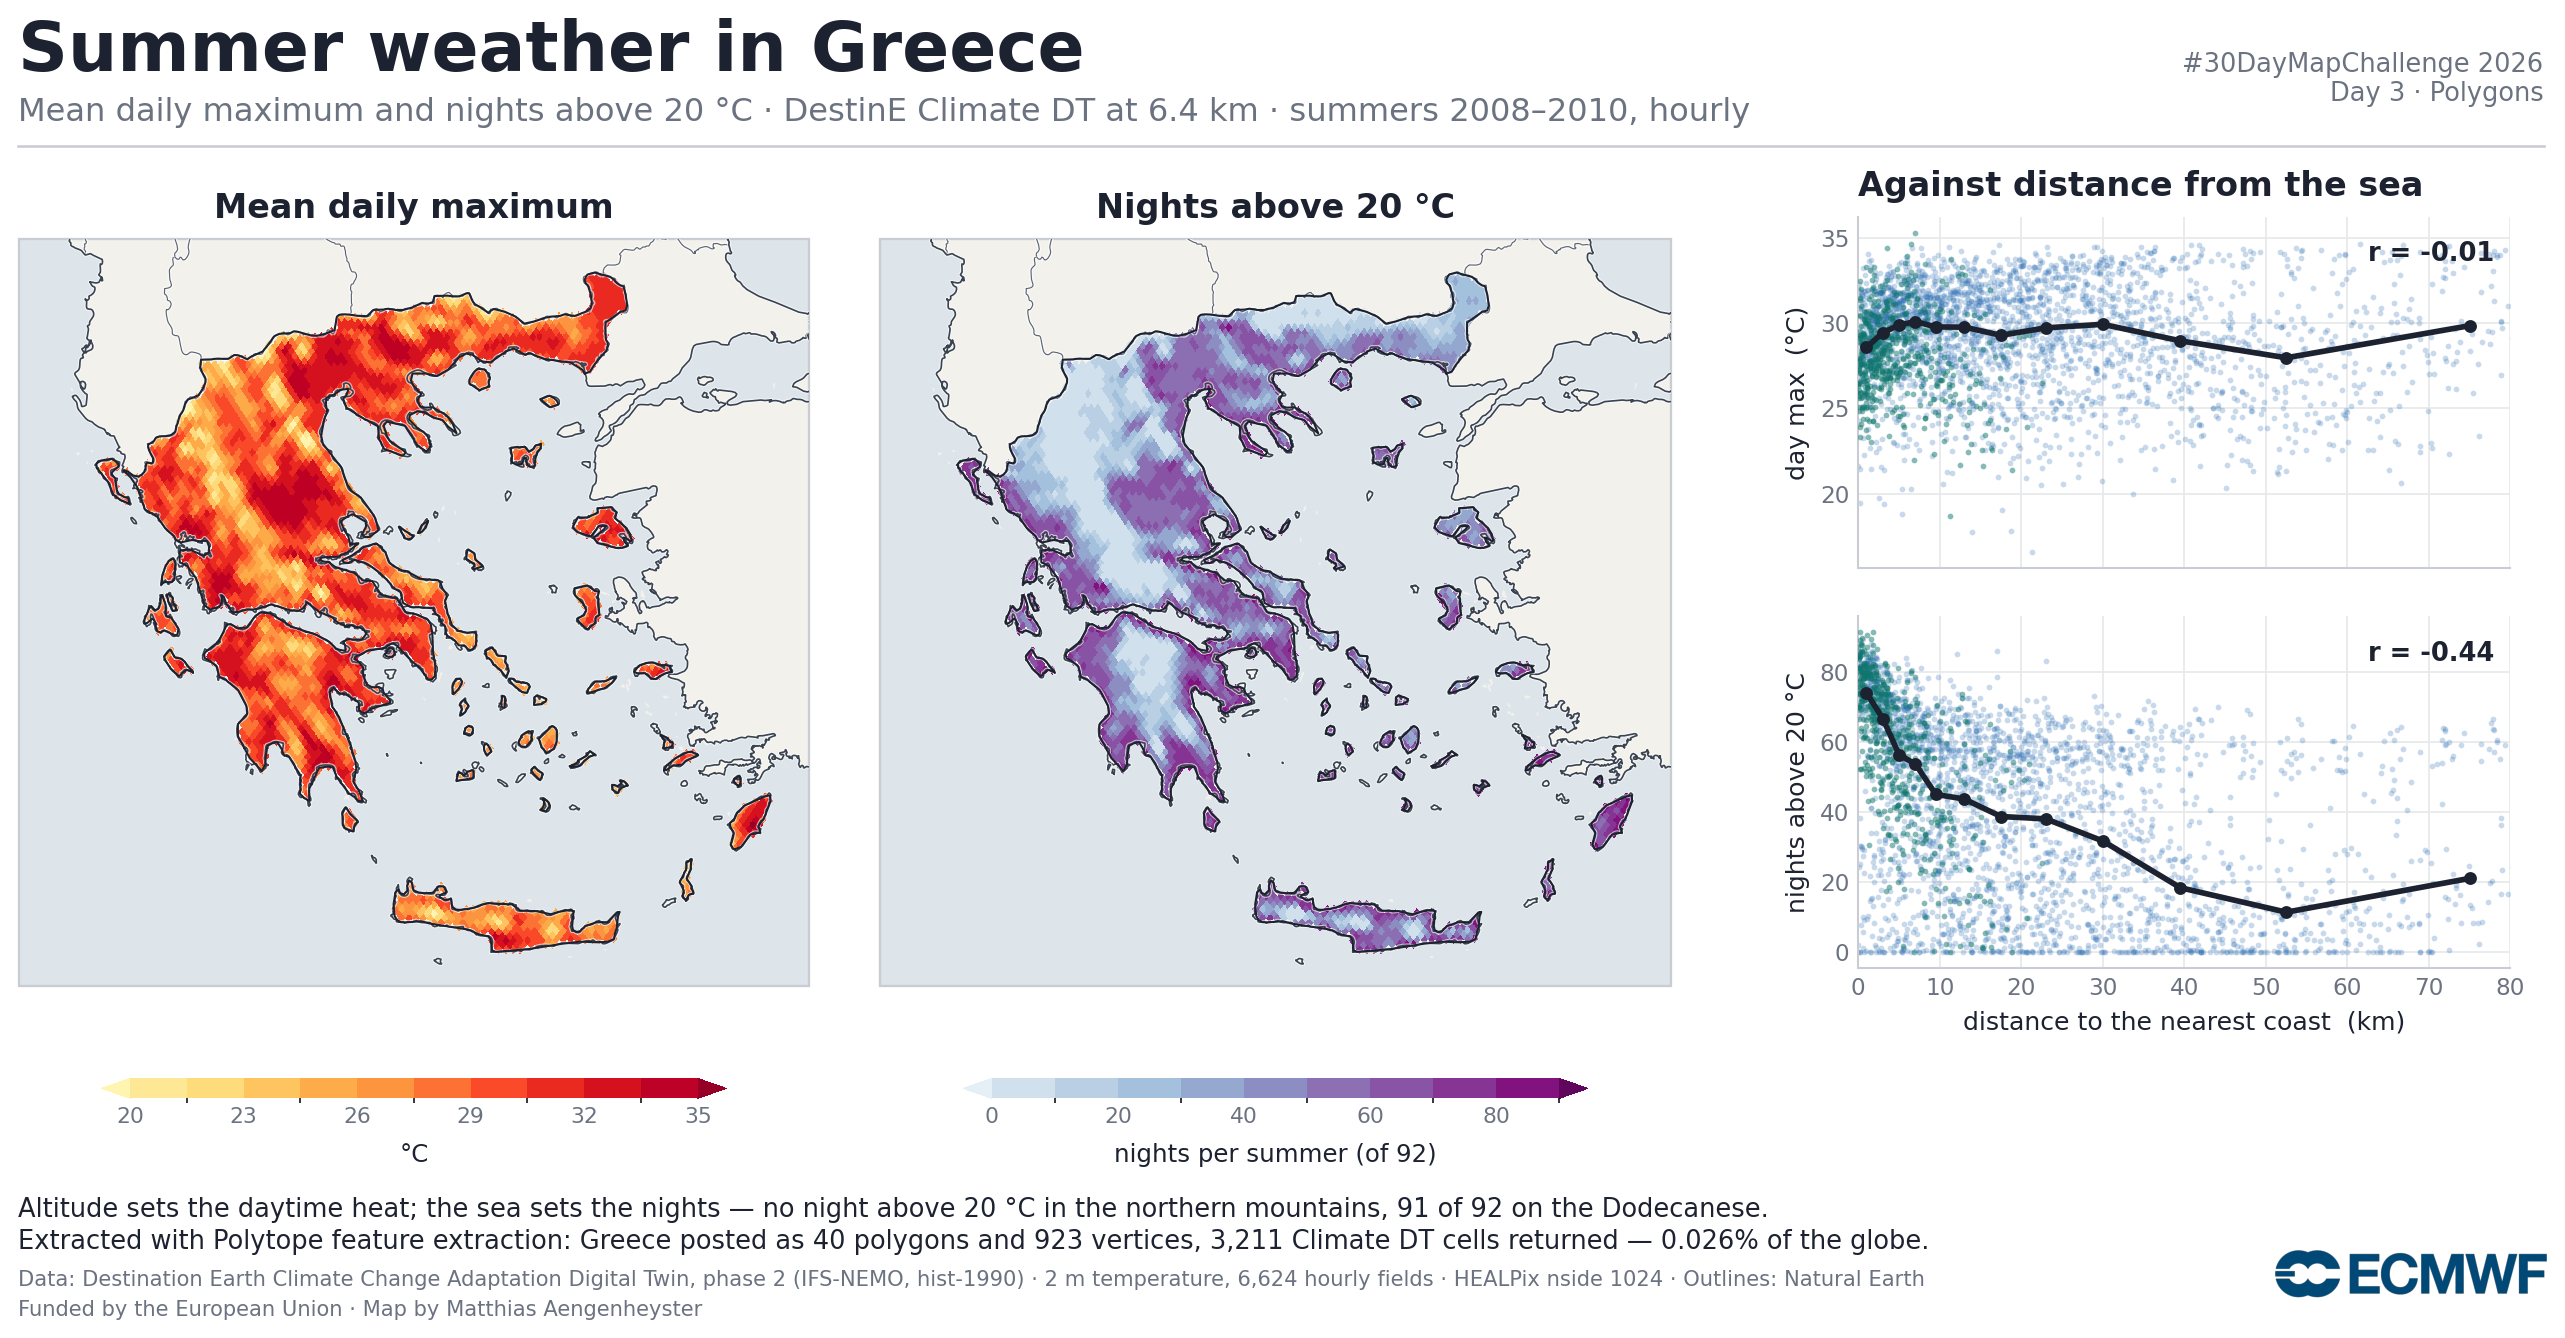

In [7]:
import matplotlib.pyplot as plt, matplotlib.image as mpimg
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.cm import ScalarMappable
from matplotlib.collections import LineCollection

proj = ccrs.AlbersEqualArea(central_longitude=24, standard_parallels=(36, 41))
ISLC = "#0f766e"

def ramp(name,bounds,lo=0.05,hi=0.98):
    cols=plt.get_cmap(name)(np.linspace(lo,hi,len(bounds)+1))
    cm=ListedColormap(cols[1:-1]); cm.set_under(cols[0]); cm.set_over(cols[-1])
    return cm, BoundaryNorm(bounds,cm.N)

def drawmap(ax,vals,cmap,norm):
    basemap(ax,BOX)
    img,ext=raster(PIX,vals[o],NSIDE,ax,nx=1100,ny=900)
    ax.imshow(np.ma.masked_invalid(img),extent=ext,origin="lower",cmap=cmap,norm=norm,
              zorder=3,interpolation="nearest")
    ax.add_collection(LineCollection(
        [proj.transform_points(PC,r[:,1],r[:,0])[:,:2] for r in RINGXY],
        colors=INK,linewidths=0.8,zorder=5))

def cbar(x,w,y,cm,nm,ticks,label):
    cax=fig.add_axes([x,y,w,0.015])
    cb=fig.colorbar(ScalarMappable(norm=nm,cmap=cm),cax=cax,orientation="horizontal",
                    ticks=ticks,extend="both")
    cb.set_label(label,color=INK,fontsize=9.5,labelpad=6)
    cb.ax.tick_params(labelsize=8.5,colors=MUT,length=0); cb.outline.set_visible(False)

def trend(ax,y,ylab,col,fmt="%.0f"):
    ax.scatter(dist[isl],y[isl],s=5,color=ISLC,alpha=0.50,lw=0,zorder=3)
    ax.scatter(dist[~isl],y[~isl],s=5,color=col,alpha=0.26,lw=0,zorder=2)
    edges=np.array([0,2,4,6,8,11,15,20,26,34,45,60,90]); mid=0.5*(edges[:-1]+edges[1:])
    med=[np.median(y[(dist>=a)&(dist<b)]) if ((dist>=a)&(dist<b)).sum()>5 else np.nan
         for a,b in zip(edges[:-1],edges[1:])]
    ax.plot(mid,med,"-o",color=INK,lw=2.2,ms=4.0,zorder=5)
    ax.set_xlim(0,80); ax.set_ylabel(ylab,color=INK,fontsize=9.8)
    ax.grid(True,color="#e7e9ec",lw=0.7); ax.set_axisbelow(True)
    for s_ in ("top","right"): ax.spines[s_].set_visible(False)
    for s_ in ("left","bottom"): ax.spines[s_].set_color(EDGE)
    ax.tick_params(colors=MUT,labelsize=9,length=0)
    r=np.corrcoef(dist,y)[0,1]
    ax.text(0.975,0.93,"r = %+.2f"%r,transform=ax.transAxes,ha="right",va="top",
            color=INK,fontsize=10,fontweight="bold")

fig=plt.figure(figsize=(15.0,7.2),dpi=185); fig.patch.set_facecolor("white")
W,G,X0,Y0=0.285,0.0255,0.045,0.255; H=W*15.0/7.2

TB=np.arange(20,35.1,1.5)
cm1,nm1=ramp("YlOrRd",TB,0.08,0.95)
ax=fig.add_axes([X0,Y0,W,H],projection=proj); drawmap(ax,tmax,cm1,nm1)
ax.set_title("Mean daily maximum",color=INK,fontsize=13,fontweight="bold",pad=8)
cbar(X0+0.03,W-0.06,Y0-0.068,cm1,nm1,TB[::2],"°C")

NB=np.arange(0,91,10)
cm2,nm2=ramp("BuPu",NB,0.10,0.95)
ax=fig.add_axes([X0+W+G,Y0,W,H],projection=proj); drawmap(ax,trop,cm2,nm2)
ax.set_title("Nights above 20 °C",color=INK,fontsize=13,fontweight="bold",pad=8)
cbar(X0+W+G+0.03,W-0.06,Y0-0.068,cm2,nm2,NB[::2],"nights per summer (of 92)")

CX=X0+2*(W+G)+0.042; CW=W-0.050
a1=fig.add_axes([CX,Y0+0.330,CW,0.264]); trend(a1,tmax,"day max  (°C)",ACC)
a1.set_xticklabels([])
a1.set_title("Against distance from the sea",color=INK,fontsize=13,fontweight="bold",loc="left",pad=8)
a2=fig.add_axes([CX,Y0+0.030,CW,0.264]); trend(a2,trop,"nights above 20 °C",ACC)
a2.set_xlabel("distance to the nearest coast  (km)",color=INK,fontsize=9.8)

fig.text(0.045,0.958,"Summer weather in Greece",color=INK,fontsize=27,fontweight="bold")
fig.text(0.045,0.921,"Mean daily maximum and nights above 20 °C · DestinE Climate DT at 6.4 km · "
         "summers %d–%d, hourly"%(min(YEARS),max(YEARS)),color=MUT,fontsize=12.5)
fig.text(0.955,0.958,"#30DayMapChallenge 2026",color=MUT,fontsize=10,ha="right")
fig.text(0.955,0.936,"Day 3 · Polygons",color=MUT,fontsize=10,ha="right")
fig.lines.append(plt.Line2D([0.045,0.955],[0.902,0.902],transform=fig.transFigure,color=EDGE,lw=1.0))

fig.text(0.045,0.098,"Altitude sets the daytime heat; the sea sets the nights — no night above 20 °C in the "
         "northern mountains, 91 of 92 on the Dodecanese.",color=INK,fontsize=10)
fig.text(0.045,0.074,"Extracted with Polytope feature extraction: Greece posted as %d polygons and %d "
         "vertices, %s Climate DT cells returned — %.3f%% of the globe."%(
         NR,NVERT,format(int(lat.size),","),100*lat.size/NPIX),color=INK,fontsize=10)
fig.text(0.045,0.046,"Data: Destination Earth Climate Change Adaptation Digital Twin, phase 2 (IFS-NEMO, "
         "hist-1990) · 2 m temperature, %s hourly fields · HEALPix nside 1024 · Outlines: Natural Earth"%(
         format(NHOURS,",")),color=MUT,fontsize=8.2)
fig.text(0.045,0.024,"Funded by the European Union · Map by Matthias Aengenheyster",color=MUT,fontsize=8.2)
try:
    a=fig.add_axes([0.858,0.026,0.098,0.058]); a.imshow(mpimg.imread("assets/ECMWF_Core_Logo_RGB.png")); a.axis("off")
except FileNotFoundError: pass
fig.savefig("day03_polygons_polytope.png",facecolor="white")
print("saved day03_polygons_polytope.png")

## Note

Daytime maxima are set by altitude and ignore the coast entirely — correlation with distance
to the sea, −0.01. Tropical nights are set by the sea, −0.44: none at all in the northern
mountains, 91 of 92 on the Dodecanese, 62 within 5 km of the shore against 24 beyond 45 km.
Nights are the half that matters for heat-health, which makes the coast — where the people and
the tourism are — the harder place to be.

Being straight about the polygon: a bounding box would return these same 3,211 land cells plus
10,731 more, and the analysis would run identically after discarding the rest. What the shape
buys is 4.3× less data on the wire, and more for any country that fits its bounding box worse
than Greece's 23%.

Two wrinkles. A 6.4 km cell on a 50 km² island is mostly sea as far as the model is concerned,
so the smallest islands run warm and flat. And `country_polygons` at 50 M keeps 40 rings —
Greece's smaller islands are not in the shape, so they are not in the query either.

Figure saved as `day03_polygons_polytope.png`.

*Part of a #30DayMapChallenge 2026 series built on ECMWF (and Copernicus) open data.*